# ES $(\mu,\lambda)$ for tuning the h.p.

In this notebook I will tune the size and number of the hidden layers.

A new Evolutionary cycle and new operators are implemented.

## The NN

In [12]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split

import time

In [13]:
# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays

In [14]:
# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


In [15]:
# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break



Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [16]:
# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

Using cpu device



In [17]:
# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)



# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)

In [18]:
# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


## Useful commands

In [19]:
from tqdm.notebook import tqdm
import time as time
import sys # to stop the execution of the code

In [34]:
# Display a progress bar
for i in tqdm(range(100)):
    time.sleep(0.01)

  0%|          | 0/100 [00:00<?, ?it/s]

In [40]:
def display_progress_bar(estimated_time, num_updates):
    # Calculate the sleep interval between updates
    sleep_interval = estimated_time / num_updates

    # Display the progress bar
    with tqdm(total=num_updates) as pbar:
        for i in range(num_updates):
            time.sleep(sleep_interval)
            pbar.update(1)

# Display the progress bar
estimated_time = 10
num_updates = 1000

display_progress_bar(estimated_time, num_updates)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [22]:
# Code before the exit
print("This will run")

# Stop execution
raise SystemExit("Stopping execution here.")

# Code after the exit (this will not run)
print("This will not run")


This will run


SystemExit: Stopping execution here.

/home/samuele/.local/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3534: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## The EA 

### Structures

In [23]:
class Individual:
    def __init__(self, gene, fitness=0.0):
        """
        Initialize an individual with a gene, solution, and fitness.
        
        Parameters:
        gene (float): The value in the space of the gene.
        solution (Any): The value in the space of the solution.
        fitness (float): The fitness value of the individual.
        """
        self.gene = gene
        self.solution = self.from_gene_to_solution(gene)
        self.fitness = fitness
    
    def from_gene_to_solution(self, genotype):
        """
        Convert the gene to a solution.
        """
        # For all element in the list of the genes, the solution is the list of the integer raund of the gene
        return [round(g) for g in genotype]

    def __repr__(self):
        return f"Gene: {self.gene}, Solution: {self.solution}, Fitness: {self.fitness}"

# Example usage:
individual1 = Individual(gene=[16.6,16])
individual2 = Individual(gene=[32,32.4])

print(f"Individual 1: {individual1}")
print(f"Individual 2: {individual2}")


Individual 1: Gene: [16.6, 16], Solution: [17, 16], Fitness: 0.0
Individual 2: Gene: [32, 32.4], Solution: [32, 32], Fitness: 0.0


### Initialization

In [24]:
def initialization(
        population_size,
        number_of_layers_interval,
        number_of_units_interval):
    genes = []
    
    for _ in range(population_size):
        num_layers = random.randint(number_of_layers_interval[0], number_of_layers_interval[1])
        gene = [random.randint(number_of_units_interval[0], number_of_units_interval[1]) for _ in range(num_layers)]
        genes.append(gene)
    
    individuals = [Individual(gene=g) for g in genes]
    return individuals

# Example usage:False
population_size = 5
number_of_layers_interval = [1, 5]
number_of_units_interval = [16, 512]
population = initialization(
    population_size=population_size,
    number_of_layers_interval=number_of_layers_interval,
    number_of_units_interval=number_of_units_interval)

for individual in population:
    print(individual)

Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.0
Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.0
Gene: [486, 417, 440, 171], Solution: [486, 417, 440, 171], Fitness: 0.0
Gene: [199, 314, 472, 480], Solution: [199, 314, 472, 480], Fitness: 0.0
Gene: [274, 87], Solution: [274, 87], Fitness: 0.0


### Fitness assessment

In [25]:
def fitness_evaluation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation,
        lr,
        input_size,
        #hidden_sizes,
        output_size,
        activation_function,
        initialize_weights):

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=individual.solution, # HERE MUST BE solution, not gene
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
        
    # Train the model for the specified number of epochs
    for _ in range(num_epochs_per_evaluation):
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)
    
    return validation_loss


# Example usage:
individual = population[0]
training_data = train_dataloader
validation_data = validation_dataloader
num_epochs_per_evaluation = 5
lr = 0.01
input_size = 28*28
#hidden_sizes = [512, 512]
output_size = 10
activation_function = nn.ReLU
initialize_weights = False

fitness = fitness_evaluation(
    individual=individual,
    training_data=training_data,
    validation_data=validation_data,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    lr=lr,
    input_size=input_size,
    #hidden_sizes=hidden_sizes,
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights)

print(f"\nIndividual: {individual}")
print(f"Fitness of individual: {fitness}")


Individual: Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.0
Fitness of individual: 0.6205710413608145


In [41]:
# The function returns hours, minutes, seconds, and the whole execution time in seconds
def algorithm_time_estimation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation,
        lr,
        input_size,
        #hidden_sizes,
        output_size,
        activation_function,
        initialize_weights,
        max_fitness_evaluations):


    # Time estimation
    start_time = time.time()  # Start timing

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=individual.solution, # HERE MUST BE solution, not gene
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
        
    # Train the model for the specified number of epochs
    for _ in tqdm(range(10)):
        time.sleep(0.1)
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)

    # Time estimation
    end_time = time.time()  # End timing
    execution_time = end_time - start_time  # Calculate execution time
    whole_execution_time_seconds = execution_time/10 * num_epochs_per_evaluation * max_fitness_evaluations  # Calculate whole execution time
    execution_time_minutes = int(whole_execution_time_seconds // 60)
    execution_time_remainder_seconds = whole_execution_time_seconds % 60

    if execution_time_minutes > 59:
        execution_time_hours = int(execution_time_minutes // 60)
        execution_time_remainder_minutes = execution_time_minutes % 60
        return execution_time_hours, execution_time_remainder_minutes, 0,  whole_execution_time_seconds

    return  0, execution_time_minutes, round(execution_time_remainder_seconds), whole_execution_time_seconds


# Example usage:
individual = population[0]
training_data = train_dataloader
validation_data = validation_dataloader
num_epochs_per_evaluation = 10 # try 20
lr = 0.01
input_size = 28*28
#hidden_sizes = [512, 512]
output_size = 10
activation_function = nn.ReLU
initialize_weights = False
max_fitness_evaluations = 55 # try 300

hours, minutes, seconds, whole_amount_in_seconds = algorithm_time_estimation(
    individual=individual,
    training_data=training_data,
    validation_data=validation_data,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    lr=lr,
    input_size=input_size,
    #hidden_sizes=hidden_sizes,
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights,
    max_fitness_evaluations=max_fitness_evaluations)

print(f"Number of fitness evaluations: {max_fitness_evaluations}")
print(f"Number of epochs per evaluation: {num_epochs_per_evaluation}")
print(f"\nTime estimation: {hours} hours, {minutes} minutes, {seconds} seconds (total seconds {whole_amount_in_seconds})")


  0%|          | 0/10 [00:00<?, ?it/s]

Number of fitness evaluations: 55
Number of epochs per evaluation: 10

Time estimation: 0 hours, 37 minutes, 12 seconds (total seconds 2231.9586896896362)


In [46]:
# Assess population
def evaluate_individuals(
        individuals,
        training_data,
        validation_data,
        num_epochs_per_evaluation,
        lr,
        input_size,
        #hidden_sizes,
        output_size,
        activation_function,
        initialize_weights):
    
    for individual in individuals:
        individual.fitness = fitness_evaluation(
            individual=individual,
            training_data=training_data,
            validation_data=validation_data,
            num_epochs_per_evaluation=num_epochs_per_evaluation,
            lr=lr,
            input_size=input_size,
            #hidden_sizes=hidden_sizes,
            output_size=output_size,
            activation_function=activation_function,
            initialize_weights=initialize_weights)
        
    

# Example usage:
#population: defined before 
training_data = train_dataloader
validation_data = validation_dataloader
num_epochs_per_evaluation = 5
lr = 0.01
input_size = 28*28
#hidden_sizes = [512, 512]
output_size = 10
activation_function = nn.ReLU
initialize_weights = False

evaluate_individuals(
    individuals=population,
    training_data=training_data,
    validation_data=validation_data,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    lr=lr,
    input_size=input_size,
    #hidden_sizes=hidden_sizes,
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights)

for individual in population:
    print(individual)

Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661
Gene: [486, 417, 440, 171], Solution: [486, 417, 440, 171], Fitness: 0.5901008455994281
Gene: [199, 314, 472, 480], Solution: [199, 314, 472, 480], Fitness: 0.5834000361092547
Gene: [274, 87], Solution: [274, 87], Fitness: 0.5174646981536074


### Selection

In [47]:
def find_best_individual(population, maximize):
    """
    Find the individual with the best fitness value in the population.
    
    Parameters:
    population (list): A list of Individual objects.
    
    Returns:
    Individual: The individual with the best fitness value.
    """
    if maximize:
        best_individual = max(population, key=lambda x: x.fitness)
    else:
        best_individual = min(population, key=lambda x: x.fitness)
    return best_individual

# Example usage:
#population: defined before
maximize = False

best_individual = find_best_individual(population = population, maximize = maximize)
print(f"The best individual is: {best_individual}")

The best individual is: Gene: [274, 87], Solution: [274, 87], Fitness: 0.5174646981536074


In [48]:
# Tournament selection
# number_of_selected: The number of individuals to be selected.
# percentage_of_population_size: The percentage of the population size to use for the tournament.
# heterogeneity = True: If True, the selected individuals must be unique.
def tournament_selection(population, number_of_selected, percentage_of_population_size, heterogeneity):
    selected_individuals = []
    tournament_size = max(1, int(len(population) * percentage_of_population_size))

    for _ in range(number_of_selected):
        if heterogeneity:
            # Ensure uniqueness
            best_individual = None
            while best_individual is None or best_individual in selected_individuals:
                # Randomly select individuals for the tournament
                tournament_individuals = random.sample(population, tournament_size)
                # Select the best individual from the tournament
                best_individual = min(tournament_individuals, key=lambda ind: ind.fitness)
        else:
            # Randomly select individuals for the tournament
            tournament_individuals = random.sample(population, tournament_size)
            # Select the best individual from the tournament
            best_individual = min(tournament_individuals, key=lambda ind: ind.fitness)

        selected_individuals.append(best_individual)

    return selected_individuals

# Example usage:
#population: defined before
number_of_selected = 4
percentage_of_population_size = 0.2 # 20% of the population size
heterogeneity = False

selected_individuals = tournament_selection(
    population = population,
    number_of_selected = number_of_selected,
    percentage_of_population_size = percentage_of_population_size,
    heterogeneity=heterogeneity)

print("\nPopulation:")
for individual in population:
    print(individual)

print("\nSelected individuals:")
for individual in selected_individuals:
    print(individual)


Population:
Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661
Gene: [486, 417, 440, 171], Solution: [486, 417, 440, 171], Fitness: 0.5901008455994281
Gene: [199, 314, 472, 480], Solution: [199, 314, 472, 480], Fitness: 0.5834000361092547
Gene: [274, 87], Solution: [274, 87], Fitness: 0.5174646981536074

Selected individuals:
Gene: [486, 417, 440, 171], Solution: [486, 417, 440, 171], Fitness: 0.5901008455994281
Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661
Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Gene: [274, 87], Solution: [274, 87], Fitness: 0.5174646981536074


### Evolutionary operators 

#### Crossover operators

In [49]:
def correct_layer_size(gene, lb, ub):
    if gene < lb or gene > ub:
        if gene < lb:
            gene = lb
        else:
            gene = ub
    return gene
    
# Example of usage 
gene = 1000
lb = 16
ub = np.inf

corrected_gene = correct_layer_size(gene = gene, lb = lb, ub = ub)

print(f"Range: [{lb}, {ub}]")
print(f"\nGene: {gene}, \nCorrected gene: {corrected_gene}")




Range: [16, inf]

Gene: 1000, 
Corrected gene: 1000


In [50]:
def correct_layers_size(genotype, lb, ub):
    corrected_genotype = [lb if gene < lb else ub if gene > ub else gene for gene in genotype]
    return corrected_genotype

# Example of usage
genotype = [0, 20, 150]
lb = 10
ub = 100

corrected_genotype = correct_layers_size(genotype = genotype, lb = lb, ub = ub)

print(f"Range: [{lb}, {ub}]")
print(f"\nGenotype: {genotype}, \nCorrected genotype: {corrected_genotype}")

Range: [10, 100]

Genotype: [0, 20, 150], 
Corrected genotype: [10, 20, 100]


In [51]:
# Description:
# aaa|aa 
# bbb|bb
# --> aaa|bb, bbb|aa
def single_point_crossover(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    child_gene1 = gene1[:point] + gene2[point:]
    child_gene2 = gene2[:point] + gene1[point:]
    child1 = Individual(gene=child_gene1)
    child2 = Individual(gene=child_gene2)
    return child1, child2

# Exmaple usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = single_point_crossover(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring2 CX: {offspring1}")
print(f"Offspring1 CX: {offspring2}")

Parent 1: Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Parent 2: Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661

Offspring2 CX: Gene: [404, 471, 264], Solution: [404, 471, 264], Fitness: 0.0
Offspring1 CX: Gene: [510, 277, 231, 36], Solution: [510, 277, 231, 36], Fitness: 0.0


In [52]:
def single_point_crossover_fitness_based_with_E(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    
    # Determine the fittest parent
    if parent1.fitness < parent2.fitness:
        fitter_parent = parent1
        other_parent = parent2
    else:
        fitter_parent = parent2
        other_parent = parent1

    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    
    # Split genes at the crossover point
    first_part_fitter = fitter_parent.gene[:point]
    second_part_fitter = fitter_parent.gene[point:]
    
    first_part_other = other_parent.gene[:point]
    second_part_other = other_parent.gene[point:]
    
    # Compute averages for the second part of genes
    avg_second_part = [(a + b) / 2 for a, b in zip(second_part_fitter, second_part_other)]
    avg_first_part = [(a + b) / 2 for a, b in zip(first_part_fitter, first_part_other)]
    
    # Create new genes for the children
    child_gene1 = first_part_fitter + avg_second_part
    child_gene2 = avg_first_part + second_part_fitter
    
    # Create child individuals
    child1 = Individual(gene=child_gene1)  # Fitness can be computed later
    child2 = Individual(gene=child_gene2)
    
    return child1, child2

# Example usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = single_point_crossover_fitness_based_with_E(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")

Parent 1: Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Parent 2: Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661

Offspring1: Gene: [510, 374.0, 247.5], Solution: [510, 374, 248], Fitness: 0.0
Offspring2: Gene: [457.0, 277, 264], Solution: [457, 277, 264], Fitness: 0.0


**Single point crossover - line recombination explanation**

The function `singlePointCrossover_lineRecombination` performs a single-point crossover with line recombination. It takes three inputs: `parent1`, `parent2`, and `k`, a parameter that controls the range of the uniform distribution used in line recombination. `gene1` and `gene2` are extracted from `parent1` and `parent2` respectively, representing the individuals' genetic information.

The function compares the fitness of the two parents and stores the fitter parent in `fitter_parent` and the other parent in `other_parent`. If either parent has only one gene (or layer), the function returns the parents as they are, without performing crossover.

A random crossover point is selected within the range of the shorter gene length of the two parents. The genes of both parents are split into two parts at the crossover point. `first_part_fitter` and `second_part_fitter` are the two parts of the fitter parent's gene, and `first_part_other` and `second_part_other` are the two parts of the other parent's gene.

Maximum lengths of the first and second parts are determined. Random coefficients (`ks_first_part` and `ks_second_part`) are generated from a uniform distribution between `-k` and `1+k`. Line recombination is performed on both parts of the genes using the formula: `kk * a + (1 - kk) * (b - a)`, where `a` and `b` are corresponding elements from the other parent's and fitter parent's gene parts, and `kk` is the random coefficient. `line_recombination_first_part` and `line_recombination_second_part` store the recombined gene parts.

`child_gene1` is created by concatenating `first_part_fitter` and `line_recombination_second_part`, and `child_gene2` is created by concatenating `line_recombination_first_part` and `second_part_fitter`. New child individuals (`child1` and `child2`) are created with the newly formed genes. Their fitness can be computed later. The function returns the two child individuals. This function is a genetic algorithm crossover operator that combines single-point crossover and line recombination to generate new offspring from two parent individuals. The `k` parameter allows control over the degree of mixing between the parents' genes.

In [64]:
# k = 0.5 is good, k = 0 is intermediate recombination 
def singlePointCrossover_lineRecombination(parent1, parent2, k, lb, ub):
    gene1, gene2 = parent1.gene, parent2.gene
    
    # Determine the fittest parent
    if parent1.fitness < parent2.fitness:
        fitter_parent = parent1
        other_parent = parent2
    else:
        fitter_parent = parent2
        other_parent = parent1

    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    
    # Split genes at the crossover point
    first_part_fitter = fitter_parent.gene[:point]
    second_part_fitter = fitter_parent.gene[point:]
    
    first_part_other = other_parent.gene[:point]
    second_part_other = other_parent.gene[point:]
    
    # Compute averages for the second part of genes

    max_len_first_part = max(len(first_part_fitter), len(first_part_other))
    max_len_second_part = max(len(second_part_fitter), len(second_part_other))
    ks_first_part =  [random.uniform(-k, 1 + k) for _ in range(max_len_first_part)]
    ks_second_part =  [random.uniform(-k, 1 + k) for _ in range(max_len_second_part)]
    
    line_recombination_first_part = [
        kk * a + (1 - kk) * b
        for a, b, kk in zip(first_part_other, first_part_fitter, ks_first_part)]
    line_recombination_second_part = [
        kk * a + (1 - kk) * b
        for a, b, kk in zip(second_part_other, second_part_fitter, ks_second_part)]
    
    
    # Create new genes for the children
    child_gene1 = first_part_fitter + line_recombination_second_part
    child_gene2 = line_recombination_first_part + second_part_fitter

    child_gene1 = correct_layers_size(genotype=child_gene1, lb=lb, ub=ub)
    child_gene2 = correct_layers_size(genotype=child_gene2, lb=lb, ub=ub)
    
    # Create child individuals
    child1 = Individual(gene=child_gene1)  # Fitness can be computed later
    child2 = Individual(gene=child_gene2)
    
    return child1, child2

# Example usage
parent1 = population[0]
parent2 = population[1]
k = 0
lb = 16
ub = np.inf
offspring1, offspring2 = singlePointCrossover_lineRecombination(parent1 = parent1, parent2 = parent2, k = k, lb = lb, ub = ub )


print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")

Parent 1: Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Parent 2: Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661

Offspring1: Gene: [510, 277, 246.7809266762156], Solution: [510, 277, 247], Fitness: 0.0
Offspring2: Gene: [421.1862854900953, 378.76734418774413, 264], Solution: [421, 379, 264], Fitness: 0.0


#### Mutation operators

The integer mutation is an evolutionary operator quite complicated that i built for the case of the optimization of the number of units of a nueral network when the the genotype is a real number. 
The input is 
```python
individual, mutation_probability, mutation_range_per_layer, minimum_gene, maximum_gene
```
Given a genotype, for instance [120,130,110], a mutation probabbility, for instance 0.1 and a utation range layer for instance [30,20,10,20,20] for instance, the procedure is the following:
- Start with layer 1 (units = 120)
- With probability 0.1
  - units = units + [-30,30]
  
The, repeat for each layer. 

Moreover, 
- At the beginning, the last elements of the array [30,20,10,20,20] are removed if the len of this is larger then the len of [120,130,110].
- it is forced that each new gene must belong in [minimum_gene, maximum_gene]

In [65]:
def preProcess_selfAdaptive_mutation(population):
    # Find the maximum lenght of the genes of the population 
    max_len = max([len(ind.gene) for ind in population])

    # Find the mean of each gene of the genotype
    genotype_mean = [np.mean([ind.gene[i] for ind in population if i < len(ind.gene)]) for i in range(max_len)]

    # Find the maximum of each gene of the genotype
    genotype_max = [np.max([ind.gene[i] for ind in population if i < len(ind.gene)]) for i in range(max_len)]
    

    return genotype_mean, genotype_max

# Example usage
#population: defined before
genotype_mean, genotype_max = preProcess_selfAdaptive_mutation(population)

print("Population:")
for individual in population:
    print(individual)

print("\nGenotype mean:")
print(genotype_mean)    

print("\nGenotype max:")
print(genotype_max)    


Population:
Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661
Gene: [486, 417, 440, 171], Solution: [486, 417, 440, 171], Fitness: 0.5901008455994281
Gene: [199, 314, 472, 480], Solution: [199, 314, 472, 480], Fitness: 0.5834000361092547
Gene: [274, 87], Solution: [274, 87], Fitness: 0.5174646981536074

Genotype mean:
[374.6, 313.2, 351.75, 229.0]

Genotype max:
[510, 471, 472, 480]


In [74]:
def selfAdaptive_gaussian_mutation(parent, genotype_mean, lb, ub):
    gene = parent.gene
    mutated_gene = []
    for i in range(len(gene)):
        mutated_gene.append(gene[i] + np.random.normal(0, genotype_mean[i]/10))
        mutated_gene[i] = correct_layer_size(gene=mutated_gene[i], lb=lb, ub=ub)
    return Individual(gene=mutated_gene)
    
# Example usage
parent = population[0]
#genotype_mean: defined before
lb = 16
ub = np.inf

mutated_individual = selfAdaptive_gaussian_mutation(parent=parent, genotype_mean=genotype_mean, lb=lb, ub=ub)

print(f"Gentype mean: {genotype_mean}\n")

for g1, g2 in zip(parent.gene, mutated_individual.gene):
    print(f"Gene: {g1} -> {g2}")


Gentype mean: [374.6, 313.2, 351.75, 229.0]

Gene: 404 -> 431.3117324591705
Gene: 471 -> 475.0397447649221
Gene: 231 -> 271.0784190788106
Gene: 36 -> 16


In [67]:
# This mutation removes a gene
def shrink_mutation(individual):
    mutated_gene = individual.gene.copy()
    if len(mutated_gene) <= 1:
        return Individual(gene=mutated_gene)  # No mutation if there's only one layer
    
    index = random.randint(0, len(mutated_gene) - 1)
    mutated_gene.pop(index)
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
mutated_individual = shrink_mutation(individual)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Mutated individual: Gene: [404, 231, 36], Solution: [404, 231, 36], Fitness: 0.0


In [68]:
# This mutation adds a gene
def gaussian_grow_mutation(individual, genotype_mean, position, lb, ub):
    mutated_gene = individual.gene.copy()
    
    # Determine the index to insert the new gene 
    if position == 'beginning':
        index = 0
    elif position == 'end':
        index = len(mutated_gene)
    else:  # Default to inserting at a random position
        index = random.randint(0, len(mutated_gene))

    # If condition 
    # It can happen that the new layer is the last one AND the largest individual has less number of layer 
    # So, we don't have data on the average of the population for that position  
    if index == len(mutated_gene) and len(mutated_gene) >= len(genotype_mean):
        inspiration_index = random.randint(0, len(genotype_mean) - 1) # Randomly select an index from the genotype
        new_layer_size = np.random.normal(genotype_mean[inspiration_index], genotype_mean[inspiration_index]/10)
        new_layer_size = correct_layer_size(gene=new_layer_size, lb=lb, ub=ub)
        mutated_gene.insert(index, new_layer_size)
    else:
        new_layer_size = np.random.normal(genotype_mean[index], genotype_mean[index]/10)
        new_layer_size = correct_layer_size(gene=new_layer_size, lb=lb, ub=ub)
        mutated_gene.insert(index, new_layer_size)
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
#genotype_max: defined before
#genotype_mean: defined before
position = 'random'
lb = 16
ub = np.inf

mutated_individual = gaussian_grow_mutation(individual=individual, genotype_mean=genotype_mean, position=position, lb=lb, ub=ub)

print(f"Genotype mean: {genotype_mean}\n")

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")



Genotype mean: [374.6, 313.2, 351.75, 229.0]

Individual: Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Mutated individual: Gene: [404, 471, 231, 36, 262.6483158307165], Solution: [404, 471, 231, 36, 263], Fitness: 0.0


### Generate offsprings

In [73]:
def generate_offsprings(
        population,
        number_of_offsprings,
        tournament_percentage,
        p_crossover_vs_mutation,
        k_crossover,
        lb_size,
        ub_size,
        p_changeLength_mutation,
        grow_position):
    
    offsprings = []

    # Pre-process the population
    genotype_mean, _ = preProcess_selfAdaptive_mutation(population)

    for _ in range(number_of_offsprings // 2):
        # Select parents for crossover
        parent1, parent2 = tournament_selection(population = population, number_of_selected=2, percentage_of_population_size=tournament_percentage, heterogeneity=False)

        if random.random() < p_crossover_vs_mutation:
            offspring1, offspring2 = singlePointCrossover_lineRecombination(parent1 = parent1, parent2 = parent2, k = k_crossover, lb = lb_size, ub = ub_size)
        else:
            if random.random() < p_changeLength_mutation:
                offspring1 = shrink_mutation(individual = parent1)
                offspring2 = gaussian_grow_mutation(individual = parent2, genotype_mean = genotype_mean, position=grow_position, lb=lb_size, ub=ub_size)
            else: 
                offspring1 = selfAdaptive_gaussian_mutation(parent = parent1, genotype_mean = genotype_mean, lb = lb_size, ub = ub_size)
                offspring2 = selfAdaptive_gaussian_mutation(parent = parent2, genotype_mean = genotype_mean, lb = lb_size, ub = ub_size)
            

        # Perform crossover or mutation        
        if number_of_offsprings % 2 == 1:
            if random.random() < p_changeLength_mutation:
                offspring1 = shrink_mutation(individual= parent1)
                offspring2 = gaussian_grow_mutation(individual = parent2, genotype_mean = genotype_mean, position=grow_position, lb=lb_size, ub=ub_size)
            else: 
                offspring1 = selfAdaptive_gaussian_mutation(parent = parent1, genotype_mean = genotype_mean, lb = lb_size, ub = ub_size)
                offspring2 = selfAdaptive_gaussian_mutation(parent = parent2, genotype_mean = genotype_mean, lb = lb_size, ub = ub_size)

        # Add the offspring to the population
        offsprings.append(offspring1)
        offsprings.append(offspring2)

    return offsprings



# Example usage
#population: defined before
number_of_offsprings = 10
tournament_percentage = 0.2
p_crossover_vs_mutation = 0.5
k_crossover = 0.5
lb_size = 10
ub_size  = 700
p_changeLength_mutation = 0.25
grow_position = 'random'

offsprings = generate_offsprings(
    population = population,
    number_of_offsprings = number_of_offsprings,
    tournament_percentage = tournament_percentage,
    p_crossover_vs_mutation = p_crossover_vs_mutation,
    k_crossover = k_crossover,
    lb_size = lb_size,
    ub_size = ub_size,
    p_changeLength_mutation = p_changeLength_mutation,
    grow_position = grow_position)


print("\nPopulation:")
for individual in population:
    print(individual)

print("\nOffsprings:")
for offspring in offsprings:
    print(offspring)
    
    


Population:
Gene: [404, 471, 231, 36], Solution: [404, 471, 231, 36], Fitness: 0.6191934320203801
Gene: [510, 277, 264], Solution: [510, 277, 264], Fitness: 0.5352858423869661
Gene: [486, 417, 440, 171], Solution: [486, 417, 440, 171], Fitness: 0.5901008455994281
Gene: [199, 314, 472, 480], Solution: [199, 314, 472, 480], Fitness: 0.5834000361092547
Gene: [274, 87], Solution: [274, 87], Fitness: 0.5174646981536074

Offsprings:
Gene: [274, 265.04319964728677], Solution: [274, 265], Fitness: 0.0
Gene: [407.16333061317823, 87], Solution: [407, 87], Fitness: 0.0
Gene: [274, 87.0], Solution: [274, 87], Fitness: 0.0
Gene: [274.0, 87], Solution: [274, 87], Fitness: 0.0
Gene: [373.53954027461475, 416.93282889497186, 237.24096455377577, 26.799216560830804], Solution: [374, 417, 237, 27], Fitness: 0.0
Gene: [342.93276992265197, 485.49434024306726, 199.08578003281946, 37.18954956373158], Solution: [343, 485, 199, 37], Fitness: 0.0
Gene: [510, 277, 264.0], Solution: [510, 277, 264], Fitness: 0.0


### Complete algorithm

In [78]:
# Ea for finding the best actiavtion function 

def es_lambdaMu_forNNStructure(
        max_fitness_evaluations,
        mu_population_size,
        init_layersNumber_interval,
        init_unitsNumber_interval,
        nn_training_data,
        nn_validation_data,
        num_epochs_per_nn_evaluation,
        nn_learning_rate,
        nn_input_size,
        #nn_hidden_sizes,
        nn_output_size,
        nn_activation_function,
        nn_initialize_weights,
        maximize_fitness,
        lambda_offsprings_size,
        tornamentPercentage_for_offspringGeneration,
        p_crossover_vs_mutation,
        k_value_for_crossover,
        units_lower_bound_per_layer,
        units_upper_bound_per_layer,
        p_changeLength_mutation,
        mutation_grow_position,
        tornamentPercentage_for_offspringSelection,
        tornamentHeterogeneity_for_offspringSelection):
    

    # Initialize the population
    fitness_evaluations = 0
    gen_index = 1

    population = initialization(
        population_size = mu_population_size,
        number_of_layers_interval = init_layersNumber_interval,
        number_of_units_interval = init_unitsNumber_interval)
    
    # Time estimation
    hours, minutes, seconds, _ = algorithm_time_estimation(
        individual=population[0],
        training_data=nn_training_data,
        validation_data=nn_validation_data,
        num_epochs_per_evaluation=num_epochs_per_nn_evaluation,
        lr=nn_learning_rate,
        input_size=nn_input_size,
        #hidden_sizes=nn_hidden_sizes,
        output_size=nn_output_size,
        activation_function=nn_activation_function,
        initialize_weights=nn_initialize_weights,
        max_fitness_evaluations= max_fitness_evaluations + 1)
    print(f"\nTime estimation: {hours} hours, {minutes} minutes, {seconds} seconds.")
    
    # Evaluate the individuals
    evaluate_individuals(
        individuals = population,
        training_data = nn_training_data,
        validation_data = nn_validation_data,
        num_epochs_per_evaluation = num_epochs_per_nn_evaluation,
        lr = nn_learning_rate,
        input_size = nn_input_size,
        #hidden_sizes = nn_hidden_sizes,
        output_size = nn_output_size,
        activation_function = nn_activation_function,
        initialize_weights = nn_initialize_weights)
    
    fitness_evaluations += mu_population_size
    
    best_individual = find_best_individual(population = population, maximize = maximize_fitness)

    print(f"\nGeneration: {gen_index} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
    for individual in population:
        print(individual)

    while fitness_evaluations < max_fitness_evaluations:
        # Select offsprings 
        offsprings = generate_offsprings(
            population = population,
            number_of_offsprings = lambda_offsprings_size,
            tournament_percentage = tornamentPercentage_for_offspringGeneration,
            p_crossover_vs_mutation = p_crossover_vs_mutation,
            k_crossover = k_value_for_crossover,
            lb_size = units_lower_bound_per_layer,
            ub_size = units_upper_bound_per_layer,
            p_changeLength_mutation = p_changeLength_mutation,
            grow_position = mutation_grow_position)
        
        evaluate_individuals(
            individuals = offsprings,
            training_data = nn_training_data,
            validation_data = nn_validation_data,
            num_epochs_per_evaluation = num_epochs_per_nn_evaluation,
            lr = nn_learning_rate,
            input_size = nn_input_size,
            #hidden_sizes = nn_hidden_sizes,
            output_size = nn_output_size,
            activation_function = nn_activation_function,
            initialize_weights = nn_initialize_weights)
        
        fitness_evaluations += lambda_offsprings_size
        
        population = tournament_selection(
            population = offsprings,
            number_of_selected = mu_population_size,
            percentage_of_population_size = tornamentPercentage_for_offspringSelection,
            heterogeneity = tornamentHeterogeneity_for_offspringSelection)
        
        best_individual = find_best_individual(population = population, maximize = maximize_fitness)
        print(f"\nGeneration: {gen_index + 1} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
        for individual in population:
            print(individual)
        gen_index += 1

    return best_individual

In [79]:
# Example of usage
max_fitness_evaluations = 40
mu_population_size = 10
init_layersNumber_interval = [1, 5]
init_unitsNumber_interval = [16, 512]
nn_training_data = train_dataloader
nn_validation_data = validation_dataloader
num_epochs_per_nn_evaluation = 10
nn_learning_rate = 0.01
nn_input_size = 28*28
#nn_hidden_sizes,
nn_output_size = 10
nn_activation_function = nn.ReLU
nn_initialize_weights = True
maximize_fitness = False # Because it is a minimization problem (of the validation loss)
lambda_offsprings_size = 15
tornamentPercentage_for_offspringGeneration = 0.2
p_crossover_vs_mutation = 0.5
k_value_for_crossover = 0.5
units_lower_bound_per_layer = 16
units_upper_bound_per_layer = 1024
p_changeLength_mutation = 0.25
mutation_grow_position = 'random'
tornamentPercentage_for_offspringSelection = 0.2 # try also more than 0.2
tornamentHeterogeneity_for_offspringSelection = False


best_individual = es_lambdaMu_forNNStructure(
    max_fitness_evaluations = max_fitness_evaluations,
    mu_population_size = mu_population_size,
    init_layersNumber_interval = init_layersNumber_interval,
    init_unitsNumber_interval = init_unitsNumber_interval,
    nn_training_data = nn_training_data,
    nn_validation_data = nn_validation_data,
    num_epochs_per_nn_evaluation = num_epochs_per_nn_evaluation,
    nn_learning_rate = nn_learning_rate,
    nn_input_size = nn_input_size,
    #nn_hidden_sizes = nn_hidden_sizes,
    nn_output_size = nn_output_size,
    nn_activation_function = nn_activation_function,
    nn_initialize_weights = nn_initialize_weights,
    maximize_fitness = maximize_fitness,
    lambda_offsprings_size = lambda_offsprings_size,
    tornamentPercentage_for_offspringGeneration = tornamentPercentage_for_offspringGeneration,
    p_crossover_vs_mutation = p_crossover_vs_mutation,
    k_value_for_crossover = k_value_for_crossover,
    units_lower_bound_per_layer = units_lower_bound_per_layer,
    units_upper_bound_per_layer = units_upper_bound_per_layer,
    p_changeLength_mutation = p_changeLength_mutation,
    mutation_grow_position = mutation_grow_position,
    tornamentPercentage_for_offspringSelection = tornamentPercentage_for_offspringSelection,
    tornamentHeterogeneity_for_offspringSelection = tornamentHeterogeneity_for_offspringSelection)


  0%|          | 0/10 [00:00<?, ?it/s]


Time estimation: 0 hours, 21 minutes, 51 seconds.

Generation: 1 | Fitness evalutions: 0 | Best individual: Gene: [453, 488, 219, 337], Solution: [453, 488, 219, 337], Fitness: 0.3788198957893443
Gene: [177, 17, 125, 23], Solution: [177, 17, 125, 23], Fitness: 0.40176813455021126
Gene: [437], Solution: [437], Fitness: 0.4256057174123348
Gene: [329, 66, 113, 76, 327], Solution: [329, 66, 113, 76, 327], Fitness: 0.38516874437002424
Gene: [463, 170], Solution: [463, 170], Fitness: 0.3992687474856985
Gene: [368, 109, 67], Solution: [368, 109, 67], Fitness: 0.3864001566742329
Gene: [453, 488, 219, 337], Solution: [453, 488, 219, 337], Fitness: 0.3788198957893443
Gene: [27], Solution: [27], Fitness: 0.4511404071558029
Gene: [483, 247, 425], Solution: [483, 247, 425], Fitness: 0.38511687049523313
Gene: [457], Solution: [457], Fitness: 0.41914786406336946
Gene: [84, 350, 282], Solution: [84, 350, 282], Fitness: 0.40451323130029315

Generation: 2 | Fitness evalutions: 15 | Best individual: Gen

## IMP
The problem is that the best individual is every generation an individual with only one layer, and after the test, it is not the best structure of the dl.
Indeed, the structure [256,128,64,32] is better then [512,512] that is better then [512]. 
In my opinion, there are two possible reasons why the ES prefers individual with one layer:
- The wheel selection is too small
- The num of epochs per fitness assessment are few 
  
Regarding the num of epochs, this means that there are few epochs to assess and individual. 
The problem of the larger NN is that they require longer time to become stronger then the other. 

## Change the number of epochs per fitness assessement 
I changed the number of epochs per fitness assessemnet. 
Consequently, i had to drecease the size of the population to computational time reasons. 
It seems now the model prefer NN with more layers. 
This confirms what I was expecting.

On the other hand there is premature convergence.

There are more possibility to handle this problem.
- Increase the population size 
- Use a ES $\mu + \lambda$ instead of a $(\mu, \lambda)$ + torunament selection.
  
At the moment, increasing the population is impossbile due to the computational power. 

#### ES $\mu + \lambda$ and torunament selection 
In the ES $\mu + \lambda$ the population increases generation per generation. 
Therefore, the wheel selection may become less effective beacuse it picks some bad individual sometimes. 

So, in this case i prefer using the tournament selection. 
However, the size of the tournament must be adjusted generation per generation, beacuse the size of the population grows over time. 

There are different possible percentages:
- 5-10 \% : low selection pressure (pro: high diversity, slower convergence)
- 10-15 \% : moderate selection pressure (pro: balance btw exploration and exploitation, risk of premature convergence)
- 15-20 \% : high selection pressure (pro: faster convergence, high risk of premature convergence)



##

## Tests

In [81]:
# Data 
#input_size = 28*28
hidden_sizes_std = [512,512]
hidden_sizes_tuned = best_individual.solution
#nn_activation_function = nn.ReLU
#initialize_weights = True
#nn_learning_rate = 0.01

epochs = 30

print(f"Best individual: {best_individual}")

Best individual: Gene: [375.66565859707083, 422.84226578793874, 268.0910967954276, 293.01155610083686, 246.1167805601732], Solution: [376, 423, 268, 293, 246], Fitness: 0.3717057267402081


In [82]:
# Train and test model 

model = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=hidden_sizes_std, 
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = lr)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)

# Train and test model with best hidden sizes and number of layers

model_tuned = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=hidden_sizes_tuned, 
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_tuned.parameters(), lr = lr)

tun_train_loss_history, tun_test_loss_history, tun_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model_tuned,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)

Epoch 1
-------------------------------
loss: 2.325750  [   64/48000]
loss: 1.257639  [ 6464/48000]
loss: 0.776843  [12864/48000]
loss: 0.872343  [19264/48000]
loss: 0.667877  [25664/48000]
loss: 0.665425  [32064/48000]
loss: 0.719748  [38464/48000]
loss: 0.667292  [44864/48000]
Test Error: 
 Accuracy: 79.8%, Avg loss: 0.610503 

Epoch 2
-------------------------------
loss: 0.551278  [   64/48000]
loss: 0.630049  [ 6464/48000]
loss: 0.419317  [12864/48000]
loss: 0.644252  [19264/48000]
loss: 0.544088  [25664/48000]
loss: 0.549334  [32064/48000]
loss: 0.595069  [38464/48000]
loss: 0.629690  [44864/48000]
Test Error: 
 Accuracy: 82.0%, Avg loss: 0.529275 

Epoch 3
-------------------------------
loss: 0.443922  [   64/48000]
loss: 0.522612  [ 6464/48000]
loss: 0.354352  [12864/48000]
loss: 0.578193  [19264/48000]
loss: 0.501269  [25664/48000]
loss: 0.505721  [32064/48000]
loss: 0.538267  [38464/48000]
loss: 0.611310  [44864/48000]
Test Error: 
 Accuracy: 82.8%, Avg loss: 0.495852 

Epoc

## Plot

In [83]:
import plot as plot

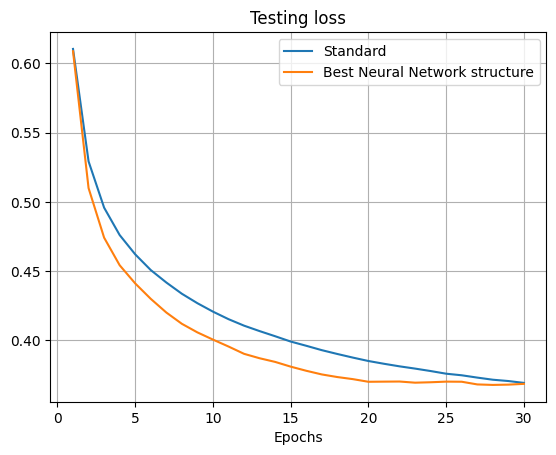

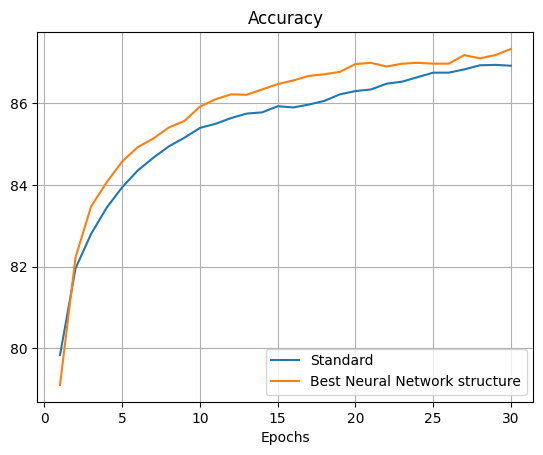

In [84]:
plot.plot_2_histories(
    std_test_loss_history, tun_test_loss_history, 'Testing loss', 'Standard', 'Best Neural Network structure')

plot.plot_2_histories(
    std_accuracy_history, tun_accuracy_history, 'Accuracy', 'Standard', 'Best Neural Network structure')